In [1]:
import numpy as np
import matplotlib.pyplot as plt

def m1_probability(R, T, F, S, B=-3.63, Ct=0.41, Cf=0.67, Cs=0.70):
    """USGS M1 model, 15-minute version. R is rainfall in mm over 15 minutes."""
    X = B + Ct*T*R + Cf*F*R + Cs*S*R
    return np.exp(X) / (1 + np.exp(X))

print(m1_probability(R=10, T=0.3, F=0.4, S=0.3))   # about 0.915
print(m1_probability(R=0,  T=0.3, F=0.4, S=0.3))   # about 0.026

0.9152894342692642
0.025831238524664058


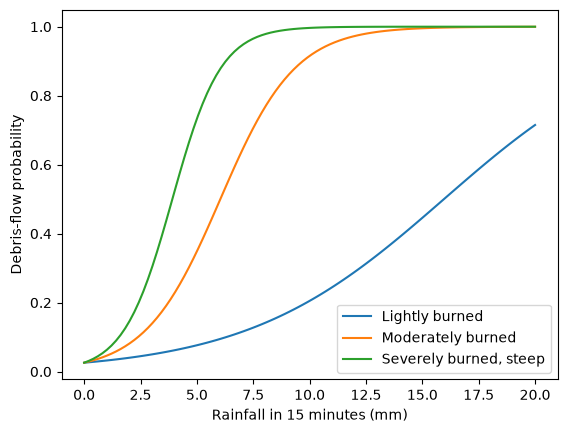

In [2]:
R = np.linspace(0, 20, 100)
basins = {
    "Lightly burned": (0.05, 0.10, 0.20),
    "Moderately burned": (0.30, 0.40, 0.30),
    "Severely burned, steep": (0.60, 0.60, 0.40),
}
for name, (T, F, S) in basins.items():
    plt.plot(R, m1_probability(R, T, F, S), label=name)
plt.xlabel("Rainfall in 15 minutes (mm)")
plt.ylabel("Debris-flow probability")
plt.legend()
plt.savefig("../notes/m1_curves.png", dpi=150)
plt.show()